In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

In [3]:
df = pd.read_csv("wine-clustering.csv")

In [4]:
df_copy = df.copy()

In [5]:
df_copy.head()

,Alcohol,Malic_Acid,Ash,Ash_Alcanity,Magnesium,Total_Phenols,Flavanoids,Nonflavanoid_Phenols,Proanthocyanins,Color_Intensity,Hue,OD280,Proline
0,14.23,1.71,2.43,15.6,127,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065
1,13.20,1.78,2.14,11.2,100,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050
2,13.16,2.36,2.67,18.6,101,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185
3,14.37,1.95,2.50,16.8,113,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480
4,13.24,2.59,2.87,21.0,118,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735


In [6]:
df_copy.isnull().sum()

Alcohol                 0
Malic_Acid              0
Ash                     0
Ash_Alcanity            0
Magnesium               0
Total_Phenols           0
Flavanoids              0
Nonflavanoid_Phenols    0
Proanthocyanins         0
Color_Intensity         0
Hue                     0
OD280                   0
Proline                 0
dtype: int64

In [7]:
df_copy.describe()

,Alcohol,Malic_Acid,Ash,Ash_Alcanity,Magnesium,Total_Phenols,Flavanoids,Nonflavanoid_Phenols,Proanthocyanins,Color_Intensity,Hue,OD280,Proline
count,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000
mean,13.000618,2.336348,2.366517,19.494944,99.741573,2.295112,2.029270,0.361854,1.590899,5.058090,0.957449,2.611685,746.893258
std,0.811827,1.117146,0.274344,3.339564,14.282484,0.625851,0.998859,0.124453,0.572359,2.318286,0.228572,0.709990,314.907474
min,11.030000,0.740000,1.360000,10.600000,70.000000,0.980000,0.340000,0.130000,0.410000,1.280000,0.480000,1.270000,278.000000
25%,12.362500,1.602500,2.210000,17.200000,88.000000,1.742500,1.205000,0.270000,1.250000,3.220000,0.782500,1.937500,500.500000
50%,13.050000,1.865000,2.360000,19.500000,98.000000,2.355000,2.135000,0.340000,1.555000,4.690000,0.965000,2.780000,673.500000
75%,13.677500,3.082500,2.557500,21.500000,107.000000,2.800000,2.875000,0.437500,1.950000,6.200000,1.120000,3.170000,985.000000
max,14.830000,5.800000,3.230000,30.000000,162.000000,3.880000,5.080000,0.660000,3.580000,13.000000,1.710000,4.000000,1680.000000


In [8]:
df_copy.shape

(178, 13)

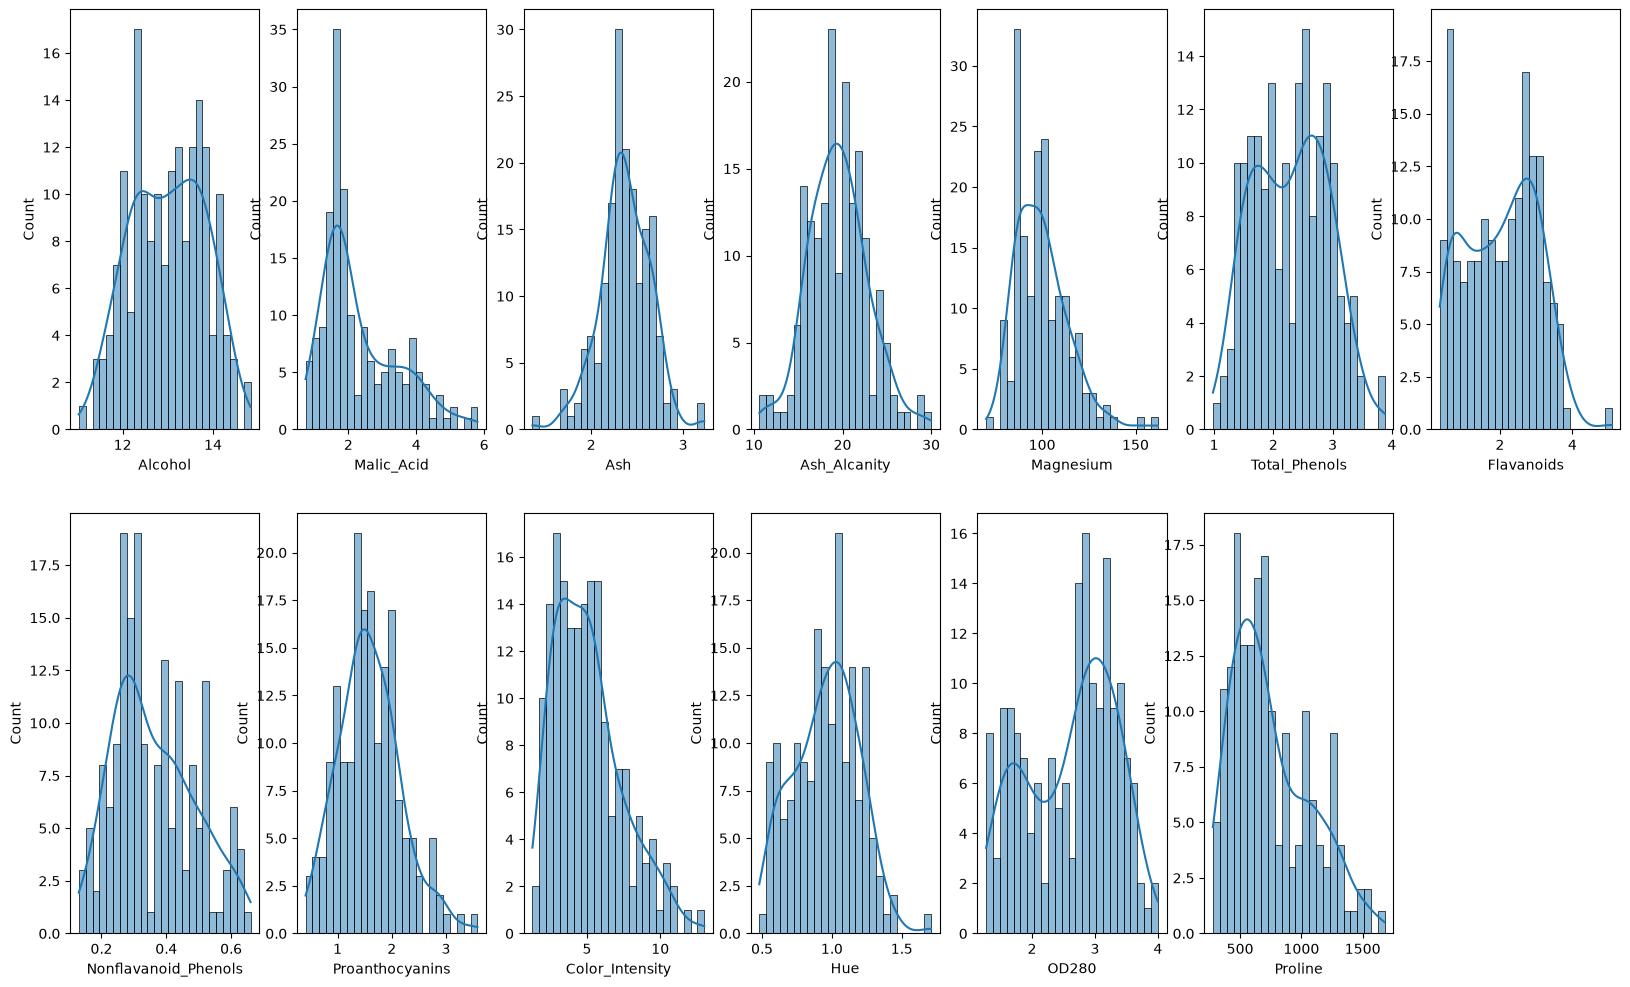

In [9]:
plt.figure(figsize=(20, 12))
for i, name in enumerate(df_copy.columns, start=1):
  plt.subplot(2, 7, i)
  sns.histplot(df_copy[name], bins=25, kde=True)

plt.tight_layout
plt.show()

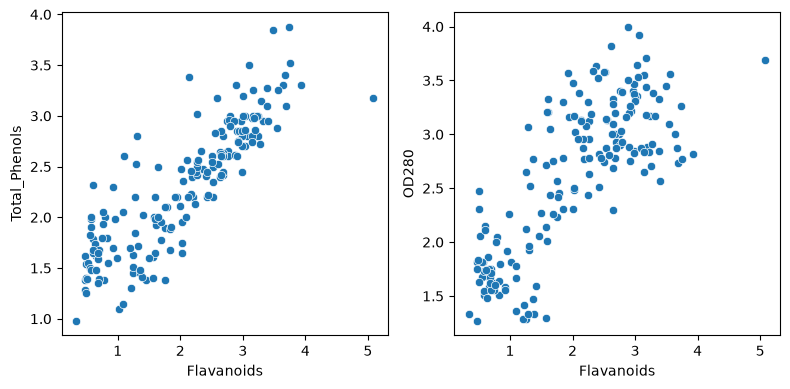

In [10]:
plt.figure(figsize=(8, 4))
columns = ["Total_Phenols", "OD280"]
for i, name in enumerate(columns, start=1):
  plt.subplot(1, 2, i)
  sns.scatterplot(data=df_copy, x="Flavanoids", y=name)

plt.tight_layout()
plt.show()


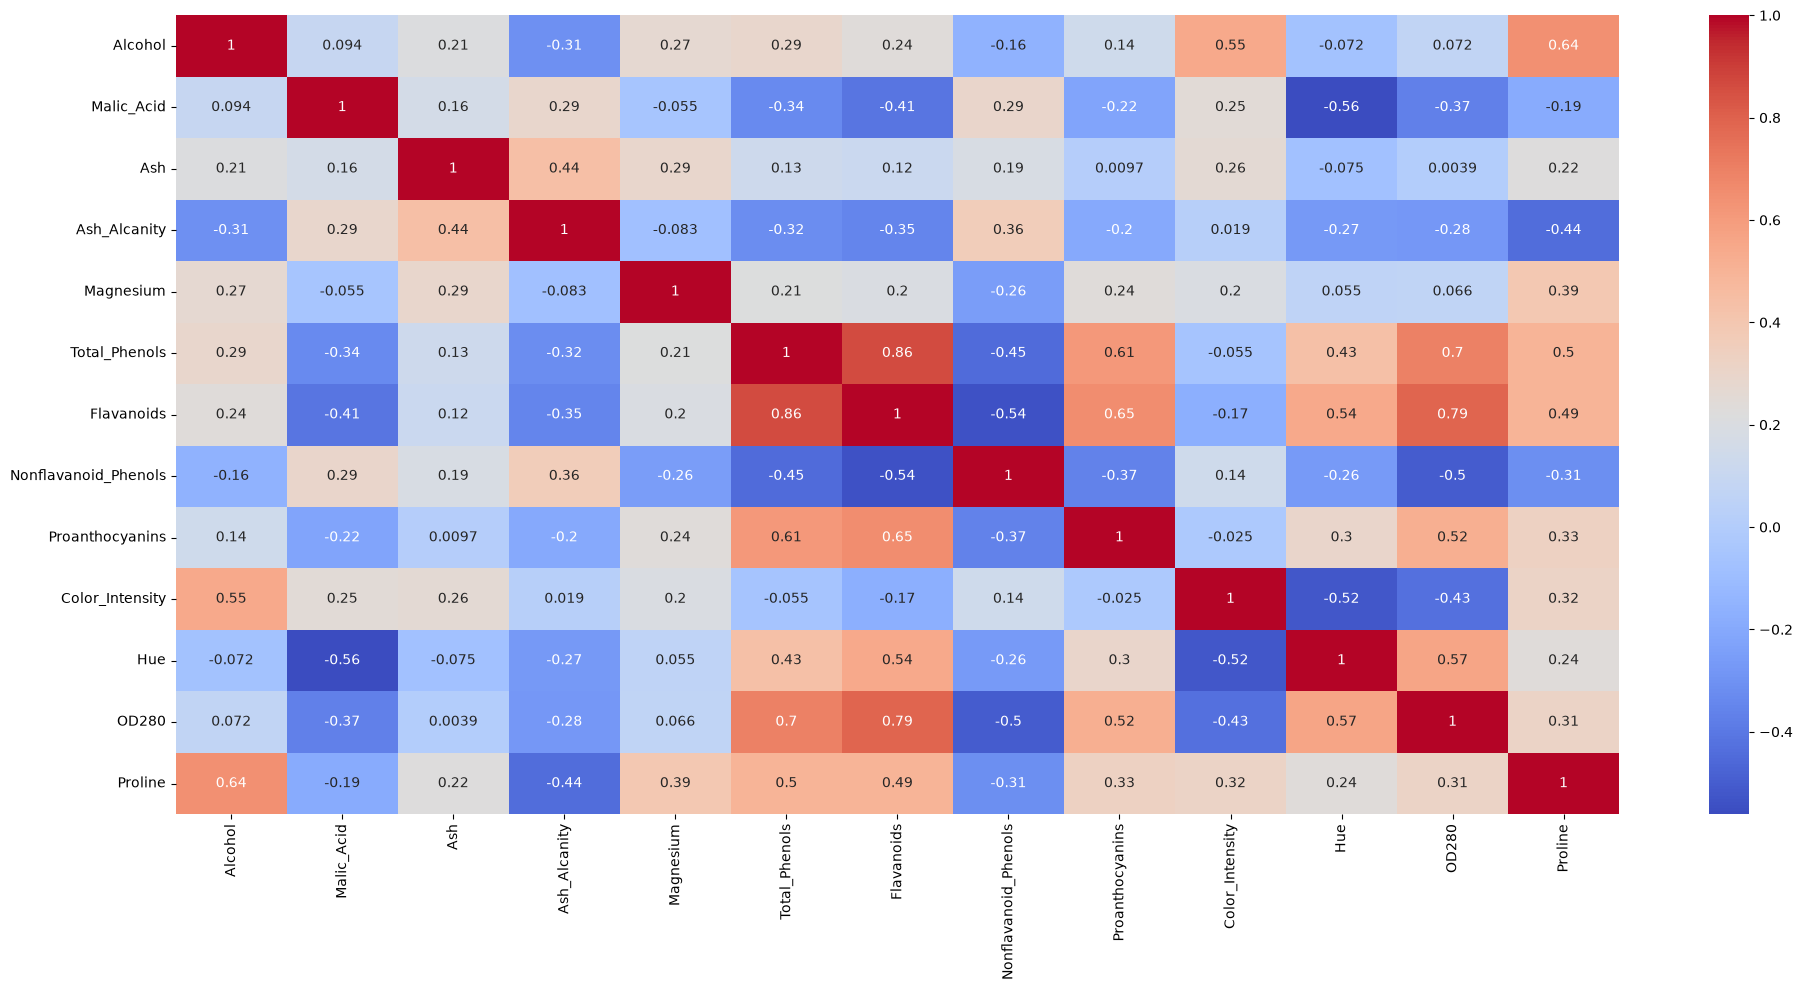

In [11]:
plt.figure(figsize=(20, 10))
sns.heatmap(df_copy.corr(), annot=True, cmap="coolwarm")

plt.tight_layout()
plt.show()

In [12]:
scaler = StandardScaler()

In [13]:
df_copy_scaled = scaler.fit_transform(df_copy)

In [14]:
df_copy_scaled

array([[ 1.51861254, -0.5622498 ,  0.23205254, ...,  0.36217728,
         1.84791957,  1.01300893],
       [ 0.24628963, -0.49941338, -0.82799632, ...,  0.40605066,
         1.1134493 ,  0.96524152],
       [ 0.19687903,  0.02123125,  1.10933436, ...,  0.31830389,
         0.78858745,  1.39514818],
       ...,
       [ 0.33275817,  1.74474449, -0.38935541, ..., -1.61212515,
        -1.48544548,  0.28057537],
       [ 0.20923168,  0.22769377,  0.01273209, ..., -1.56825176,
        -1.40069891,  0.29649784],
       [ 1.39508604,  1.58316512,  1.36520822, ..., -1.52437837,
        -1.42894777, -0.59516041]], shape=(178, 13))

In [15]:
from sklearn.decomposition import PCA

In [16]:
pca = PCA(n_components=3)

In [54]:
df_pca = pca.fit_transform(df_copy_scaled)

In [55]:
print(pca.explained_variance_ratio_)

[0.36198848 0.1920749  0.11123631]


In [56]:
print(pca.components_)

[[ 0.1443294  -0.24518758 -0.00205106 -0.23932041  0.14199204  0.39466085
   0.4229343  -0.2985331   0.31342949 -0.0886167   0.29671456  0.37616741
   0.28675223]
 [ 0.48365155  0.22493093  0.31606881 -0.0105905   0.299634    0.06503951
  -0.00335981  0.02877949  0.03930172  0.52999567 -0.27923515 -0.16449619
   0.36490283]
 [-0.20738262  0.08901289  0.6262239   0.61208035  0.13075693  0.14617896
   0.1506819   0.17036816  0.14945431 -0.13730621  0.08522192  0.16600459
  -0.12674592]]


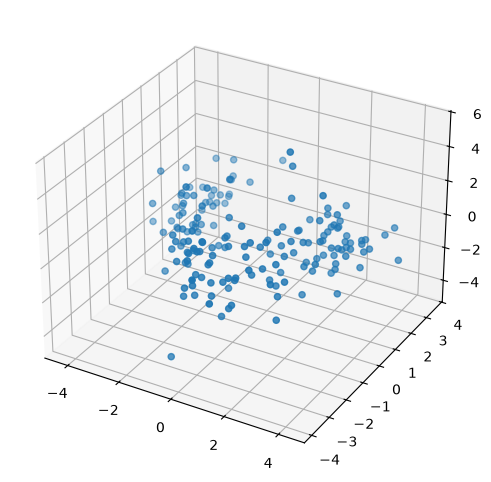

In [61]:
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection="3d")

ax.scatter(df_pca[:,0], df_pca[:,1], df_pca[:,2])

plt.show()

In [58]:
from sklearn.cluster import KMeans
from kneed import KneeLocator

In [62]:
wcss = [] 
for k in range(1, 9):
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit_predict(df_pca)
    wcss.append(kmeans.inertia_)

In [63]:
kmeans.inertia_

266.8578639221707

In [64]:
knee = KneeLocator(range(1, 9), wcss, curve="convex", direction="decreasing")
optimal_k = knee.elbow 

In [65]:
print("best k =", optimal_k)

best k = 3


Text(0, 0.5, 'WCSS')

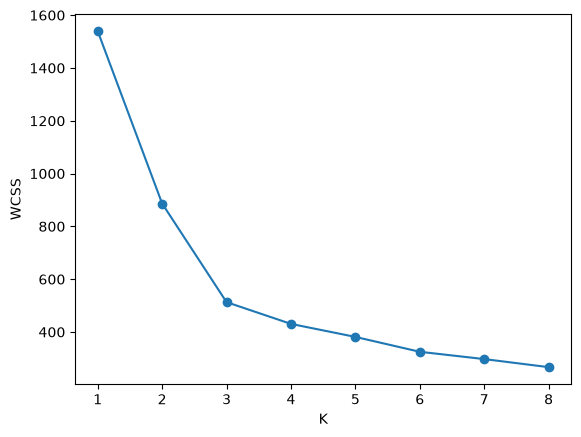

In [66]:
plt.plot(range(1, 9), wcss, marker='o')
plt.xlabel("K")
plt.ylabel("WCSS")

In [67]:
from sklearn.metrics import silhouette_score


Text(0, 0.5, 'Sihouette Score')

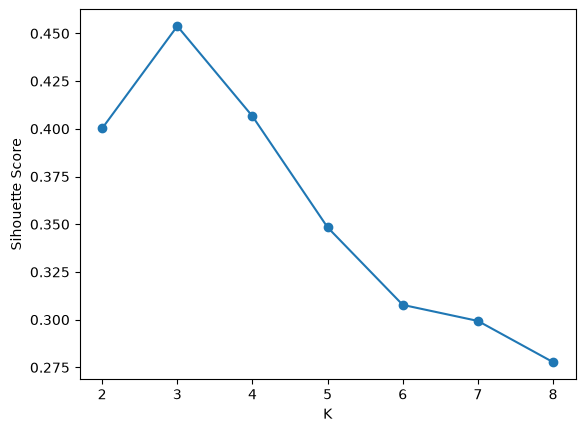

In [68]:
scores = []
for k in range(2, 9):
    kmeans = KMeans(n_clusters=k, random_state=42)
    labels = kmeans.fit_predict(df_pca)
    score = silhouette_score(df_pca, labels)
    scores.append(score)

plt.plot(range(2, 9), scores, marker='o')
plt.xlabel("K")
plt.ylabel("Sihouette Score")


Text(0, 0.5, 'SS')

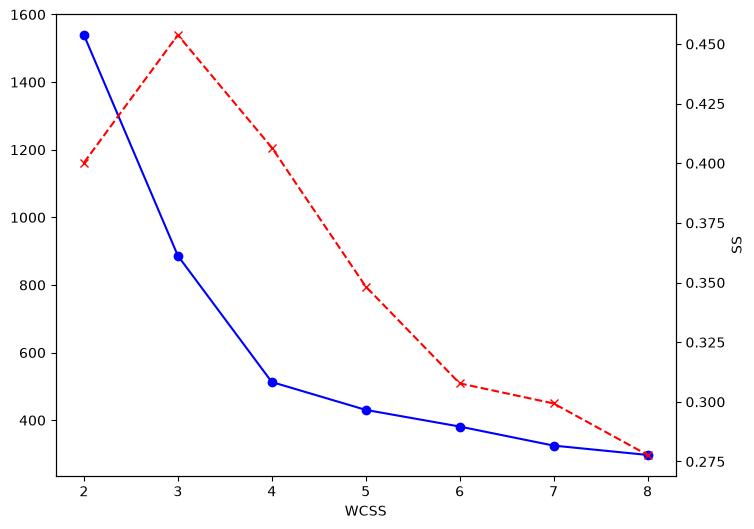

In [69]:
k_range = range(2, 9)
fig, ax1 = plt.subplots(figsize=(8, 6))

ax1.plot(k_range, wcss[:len(k_range)], marker = 'o', color = 'blue')
ax1.set_xlabel("K")
ax1.set_xlabel("WCSS")

ax2 = ax1.twinx()
ax2.plot(k_range, scores[:len(k_range)], marker = 'x', color = 'red', linestyle = '--')
ax2.set_ylabel("SS")

In [71]:
kmeans = KMeans(n_clusters=3, random_state=42)
label_kmeans = kmeans.fit_predict(df_pca)

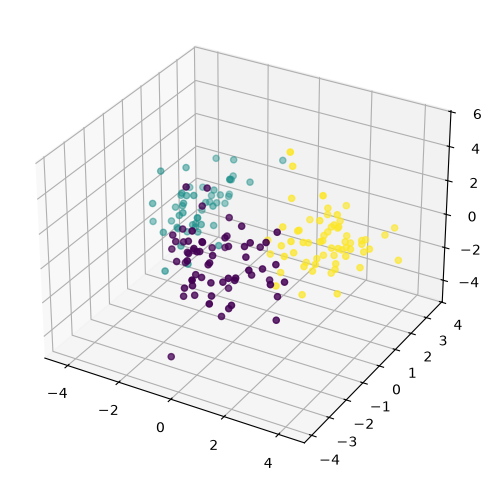

In [72]:
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection="3d")
ax.scatter(df_pca[:,0], df_pca[:,1], df_pca[:,2], c=label_kmeans)

plt.show()

In [50]:
from sklearn.cluster import AgglomerativeClustering

In [73]:
agg_clf = AgglomerativeClustering(n_clusters=3, linkage='ward')
labels_agg = agg_clf.fit_predict(df_pca)

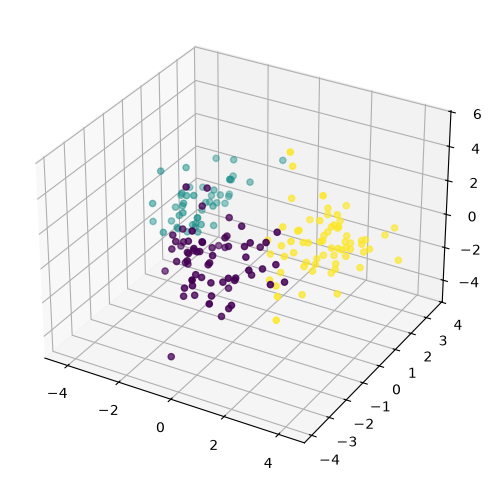

In [74]:
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection="3d")
ax.scatter(df_pca[:,0], df_pca[:,1], df_pca[:,2], c=labels_agg)

plt.show()

In [75]:
df_copy["clusters"] = labels_agg

In [76]:
df_copy.head()

,Alcohol,Malic_Acid,Ash,Ash_Alcanity,Magnesium,Total_Phenols,Flavanoids,Nonflavanoid_Phenols,Proanthocyanins,Color_Intensity,Hue,OD280,Proline,clusters
0,14.23,1.71,2.43,15.6,127,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065,2
1,13.20,1.78,2.14,11.2,100,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050,2
2,13.16,2.36,2.67,18.6,101,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185,2
3,14.37,1.95,2.50,16.8,113,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480,2
4,13.24,2.59,2.87,21.0,118,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735,2


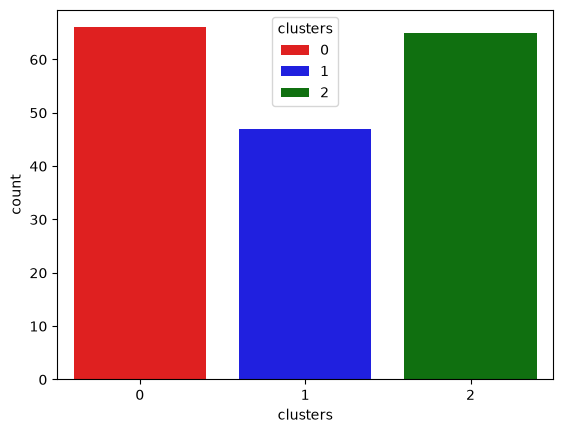

In [79]:
pal = ["red", "blue", "green"]
sns.countplot(x=df_copy["clusters"], palette=pal, hue=df_copy["clusters"])
plt.show()

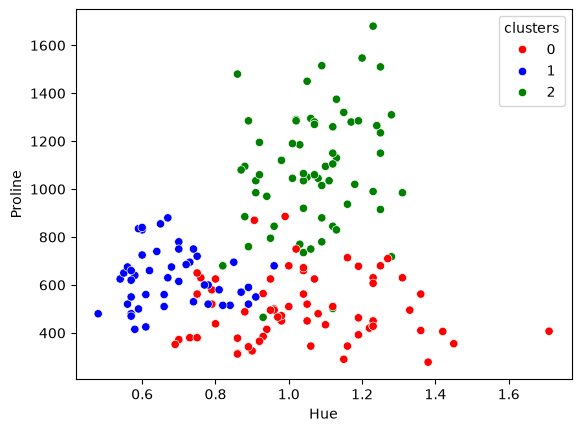

In [81]:
sns.scatterplot(x=df_copy["Hue"], y=df_copy["Proline"], hue=df_copy["clusters"], palette=pal)
plt.show()

In [82]:
cluster_summary = df_copy.groupby("clusters").mean()
print(cluster_summary)

            Alcohol  Malic_Acid       Ash  Ash_Alcanity   Magnesium  \
clusters                                                              
0         12.264242    1.932121  2.245455     20.087879   91.666667   
1         13.171489    3.431702  2.441064     21.595745   98.829787   
2         13.624769    1.954769  2.435538     17.373846  108.600000   

          Total_Phenols  Flavanoids  Nonflavanoid_Phenols  Proanthocyanins  \
clusters                                                                     
0              2.220152    1.991364              0.367727         1.540455   
1              1.674894    0.792979              0.452766         1.165957   
2              2.819692    2.961692              0.290154         1.949385   

          Color_Intensity       Hue     OD280      Proline  
clusters                                                    
0                3.036364  1.042515  2.729848   504.439394  
1                7.452553  0.682979  1.702553   627.021277  
2        